# Evaluator
### Setup
Connect your existing folder with the pre-collected experiments data.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import ast
import numpy as np
import matplotlib.pyplot as plt

DRIVE_ROOT = Path("/content/drive/MyDrive/EM43")
print("DRIVE_ROOT =", DRIVE_ROOT.resolve())

Mounted at /content/drive
DRIVE_ROOT = /content/drive/MyDrive/EM43


In [2]:
def lut_idx4(l: int, c: int, r: int) -> int:
    return (l * 4 + c) * 4 + r


IDX_000 = lut_idx4(0, 0, 0)
IDX_020 = lut_idx4(0, 2, 0)
IDX_200 = lut_idx4(2, 0, 0)
IDX_002 = lut_idx4(0, 0, 2)


def enforce_immutables_full(rule_full: np.ndarray) -> None:
    if rule_full.shape[-1] != 64:
        raise ValueError(f"rule_full last dimension must be 64, got {rule_full.shape}")
    rule_full[..., IDX_000] = 0
    rule_full[..., IDX_020] = 2
    rule_full[..., IDX_200] = 0
    rule_full[..., IDX_002] = 0


def parse_uint8_vector_string(s: str, expected_len: int | None = None, name: str = "vector") -> np.ndarray:
    s = s.strip()
    if not s:
        raise ValueError(f"{name} string is empty")

    if s[0] != "[":
        s = "[" + s + "]"

    try:
        obj = ast.literal_eval(s)
    except Exception as e:
        raise ValueError(f"Could not parse {name} string: {e}") from e

    arr = np.asarray(obj, dtype=np.int64).reshape(-1)

    if expected_len is not None and arr.shape[0] != expected_len:
        raise ValueError(f"{name} must have length {expected_len}, got {arr.shape[0]}")
    if np.any(arr < 0) or np.any(arr > 3):
        raise ValueError(f"{name} values must be in {{0,1,2,3}}")

    return arr.astype(np.uint8)


def parse_rule_program_strings(rule_str: str, prog_str: str):
    rule = parse_uint8_vector_string(rule_str, expected_len=64, name="rule")
    prog = parse_uint8_vector_string(prog_str, expected_len=None, name="program")
    enforce_immutables_full(rule)
    return rule, prog


def load_genome_from_drive(task_alias: str, run_id: int, drive_root: Path = DRIVE_ROOT):
    task_dir = drive_root / task_alias
    genome_path = task_dir / f"best_em43_{task_alias}_run_{run_id:03d}.npz"

    if not genome_path.exists():
        raise FileNotFoundError(f"Genome file not found: {genome_path}")

    data = np.load(genome_path, allow_pickle=True)

    rule_full = np.asarray(data["rule_full"], dtype=np.uint8).reshape(-1)
    program = np.asarray(data["program"], dtype=np.uint8).reshape(-1)

    if rule_full.shape != (64,):
        raise ValueError(f"Loaded rule has wrong shape: {rule_full.shape}")

    enforce_immutables_full(rule_full)

    meta = {
        "path": genome_path,
        "task_alias": str(data["task_alias"]) if "task_alias" in data else task_alias,
        "run": int(data["run"]) if "run" in data else run_id,
        "Lp": int(data["Lp"]) if "Lp" in data else int(program.shape[0]),
        "best_gen": int(data["best_gen"]) if "best_gen" in data else None,
        "fitness": float(data["fitness"]) if "fitness" in data else None,
        "mae": float(data["mae"]) if "mae" in data else None,
    }
    return rule_full, program, meta


def build_single_input_task(*, inputs, target_fn):
    xs = list(inputs)
    encoded_inputs = []
    targets = np.empty((len(xs),), dtype=np.int64)

    for i, x in enumerate(xs):
        if x < 0:
            raise ValueError(f"Input x={x} must be nonnegative")

        enc = np.zeros((x + 1,), dtype=np.uint8)
        enc[x] = 2
        encoded_inputs.append(enc)
        targets[i] = int(target_fn(x))

    return encoded_inputs, targets


def build_two_input_task(*, pairs, target_fn):
    pairs = list(pairs)
    encoded_inputs = []
    targets = np.empty((len(pairs),), dtype=np.int64)

    for i, (a, b) in enumerate(pairs):
        if a < 0 or b < 0:
            raise ValueError(f"Inputs must be nonnegative, got {(a, b)}")

        L = max(a, b) + 1
        enc = np.zeros((L,), dtype=np.uint8)
        enc[a] = 2
        enc[b] = 2
        encoded_inputs.append(enc)
        targets[i] = int(target_fn(a, b))

    return encoded_inputs, targets


class EM43NumpyEvaluator:
    """
    Pure-numpy EM43 evaluator.

    Matches training semantics:
      - same tape layout: [program][separator][encoding]
      - same LUT indexing
      - same synchronous radius-1 update
      - same halting rule: live > 0 and 2*ctrl >= live
      - same time-0 halting check
      - same immutables
      - if live == 0, continue until T_max

    Inference difference:
      - no right-boundary invalidation
      - initial usable tape length is:
            Lp + Ls + (max active input position + 1) + right_padding
      - right-only self-extension before step
      - decode over the whole usable right region from the fixed encoding origin
      - no left extension
    """

    def __init__(
        self,
        *,
        Lp: int,
        Ls: int = 4,
        T_max: int = 10000,
        right_padding: int = 20,
        extend_margin: int = 3,
        extend_by: int = 20,
    ):
        self.Lp = int(Lp)
        self.Ls = int(Ls)
        self.T_max = int(T_max)
        self.right_padding = int(right_padding)
        self.extend_margin = int(extend_margin)
        self.extend_by = int(extend_by)

        if self.Lp <= 0:
            raise ValueError("Lp must be positive")
        if self.Ls < 0:
            raise ValueError("Ls must be nonnegative")
        if self.T_max <= 0:
            raise ValueError("T_max must be positive")
        if self.right_padding < 0:
            raise ValueError("right_padding must be nonnegative")
        if self.extend_margin < 0:
            raise ValueError("extend_margin must be nonnegative")
        if self.extend_by <= 0:
            raise ValueError("extend_by must be positive")

        self.enc_origin = self.Lp + self.Ls

    def _validate_inputs(self, rule_full: np.ndarray, program: np.ndarray, enc: np.ndarray):
        if rule_full.shape != (64,):
            raise ValueError(f"rule_full shape must be (64,), got {rule_full.shape}")
        if program.ndim != 1 or program.shape[0] != self.Lp:
            raise ValueError(f"program shape must be ({self.Lp},), got {program.shape}")
        if enc.ndim != 1:
            raise ValueError(f"encoding must be 1D, got shape {enc.shape}")
        if enc.shape[0] <= 0:
            raise ValueError("encoding must be non-empty")

        if np.any(rule_full < 0) or np.any(rule_full > 3):
            raise ValueError("rule values must be in {0,1,2,3}")
        if np.any(program < 0) or np.any(program > 3):
            raise ValueError("program values must be in {0,1,2,3}")
        if np.any(enc < 0) or np.any(enc > 3):
            raise ValueError("encoding values must be in {0,1,2,3}")

    def _build_initial_tape(self, program: np.ndarray, enc: np.ndarray) -> np.ndarray:
        active = np.flatnonzero(enc != 0)
        if active.size == 0:
            enc_len_used = enc.shape[0]
        else:
            enc_len_used = int(active[-1]) + 1

        usable_len = self.Lp + self.Ls + enc_len_used + self.right_padding

        tape = np.zeros((usable_len,), dtype=np.uint8)
        tape[:self.Lp] = program
        tape[self.enc_origin:self.enc_origin + enc.shape[0]] = enc
        return tape

    @staticmethod
    def _count_live_ctrl(tape: np.ndarray):
        live = int(np.count_nonzero(tape))
        ctrl = int(np.count_nonzero(tape == 3))
        return live, ctrl

    @staticmethod
    def _rightmost_active_index(tape: np.ndarray):
        pos = np.flatnonzero(tape != 0)
        return None if pos.size == 0 else int(pos[-1])

    def _extend_if_needed(self, tape: np.ndarray) -> np.ndarray:
        r_active = self._rightmost_active_index(tape)
        if r_active is None:
            return tape

        right_edge = tape.shape[0] - 1
        if right_edge - r_active <= self.extend_margin:
            tape = np.concatenate([tape, np.zeros((self.extend_by,), dtype=np.uint8)])
        return tape

    @staticmethod
    def _step_once(rule_full: np.ndarray, tape: np.ndarray) -> np.ndarray:
        L = np.empty_like(tape)
        C = tape
        R = np.empty_like(tape)

        L[0] = 0
        L[1:] = tape[:-1]

        R[-1] = 0
        R[:-1] = tape[1:]

        idx = (L.astype(np.int32) * 4 + C.astype(np.int32)) * 4 + R.astype(np.int32)
        return rule_full[idx].astype(np.uint8, copy=False)

    def _decode(self, tape: np.ndarray):
        decode_region = tape[self.enc_origin:]
        pos = np.flatnonzero(decode_region == 2)
        return None if pos.size == 0 else int(pos[-1])

    def run_single(self, *, rule_full: np.ndarray, program: np.ndarray, enc: np.ndarray, return_trajectory: bool = False):
        rule = np.asarray(rule_full, dtype=np.uint8).copy()
        prog = np.asarray(program, dtype=np.uint8).copy()
        enc = np.asarray(enc, dtype=np.uint8).copy()

        enforce_immutables_full(rule)
        self._validate_inputs(rule, prog, enc)

        tape = self._build_initial_tape(prog, enc)
        n_extensions = 0
        trajectory = [tape.copy()] if return_trajectory else None

        live, ctrl = self._count_live_ctrl(tape)
        if live > 0 and ctrl * 2 >= live:
            pred = self._decode(tape)
            return {
                "pred": pred,
                "valid": pred is not None,
                "halted": True,
                "halt_time": 0,
                "n_extensions": n_extensions,
                "final_usable_len": int(tape.shape[0]),
                "trajectory": trajectory,
            }

        for t in range(1, self.T_max + 1):
            old_len = tape.shape[0]
            tape = self._extend_if_needed(tape)
            if tape.shape[0] != old_len:
                n_extensions += 1

            tape = self._step_once(rule, tape)

            if return_trajectory:
                trajectory.append(tape.copy())

            live, ctrl = self._count_live_ctrl(tape)
            if live > 0 and ctrl * 2 >= live:
                pred = self._decode(tape)
                return {
                    "pred": pred,
                    "valid": pred is not None,
                    "halted": True,
                    "halt_time": t,
                    "n_extensions": n_extensions,
                    "final_usable_len": int(tape.shape[0]),
                    "trajectory": trajectory,
                }

        return {
            "pred": None,
            "valid": False,
            "halted": False,
            "halt_time": None,
            "n_extensions": n_extensions,
            "final_usable_len": int(tape.shape[0]),
            "trajectory": trajectory,
        }

    def plot_trajectory(self, trajectory, *, title="EM43 trajectory", figsize=(14, 6), tick_step=10):
        if trajectory is None or len(trajectory) == 0:
            raise ValueError("trajectory is empty")

        max_len = max(row.shape[0] for row in trajectory)
        img = np.zeros((len(trajectory), max_len), dtype=np.uint8)
        for i, row in enumerate(trajectory):
            img[i, :row.shape[0]] = row

        from matplotlib.colors import ListedColormap, BoundaryNorm

        cmap = ListedColormap(["white", "black", "red", "blue"])
        norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

        fig, ax = plt.subplots(figsize=figsize)
        ax.imshow(
            img,
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
            aspect="equal",   # square cells
            origin="upper",
        )

        # Left boundary before cell 0
        ax.axvline(x=-0.5, color="gray", linewidth=2)

        # Encoding origin boundary x0 = enc_origin
        ax.axvline(x=self.enc_origin - 0.5, color="green", linewidth=2)

        ax.set_xlabel("Encoding position (relative to x0)")
        ax.set_ylabel("Time step")
        ax.set_title(title)

        ax.set_xlim(-0.5, max_len - 0.5)
        ax.set_ylim(len(trajectory) - 0.5, -0.5)

        # X ticks labeled relative to encoding origin
        tick_start = self.enc_origin
        ticks = np.arange(tick_start, max_len, tick_step)
        ax.set_xticks(ticks)
        ax.set_xticklabels((ticks - self.enc_origin).astype(int))

        plt.show()

# Run validation on the desired range
1. to validate a trained em on a task: use the same alias you used for training
2. select a run id
3. set hyperparams
4. set task formula
5. watch output

In [3]:
# ---- Genome source: file (default) ----
# ---- Genome source: file ----
task_alias = "times2"
run_id = 1

rule_full, program, meta = load_genome_from_drive(
    task_alias=task_alias,
    run_id=run_id
)

print("Loaded genome from:", meta["path"])
print("Loaded task_alias:", meta["task_alias"])
print("Loaded run:", meta["run"])
print("Loaded Lp:", meta["Lp"])
print("Loaded best_gen:", meta["best_gen"])
print("Loaded fitness:", meta["fitness"])
print("Loaded mae:", meta["mae"])

# ---- Genome source: manual (alternative) ----
#rule_str ="[0, 0, 0, 3, 1, 1, 3, 2, 2, 1, 2, 3, 2, 0, 3, 1, 1, 0, 3, 3, 1, 0, 0, 3, 3, 1, 3, 3, 1, 2, 2, 1, 0, 3, 1, 1, 2, 3, 1, 3, 2, 1, 1, 3, 3, 2, 2, 2, 3, 0, 3, 3, 0, 3, 1, 3, 2, 2, 3, 3, 1, 3, 2, 3]"

#prog_str = "[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 2, 0, 0, 1, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1]"

#rule_full, program = parse_rule_program_strings(rule_str, prog_str)
#print("Loaded genome manually.")

Lp = int(program.shape[0])

evaluator = EM43NumpyEvaluator(
    Lp=len(program),
    Ls=4,
    T_max=10000,
    right_padding=20,
    extend_margin=3,
    extend_by=20,
)

# ---- Build dataset ----
# 1-input default:
# ---- Build dataset ----
# =========================
# TEST DATA: y = 2x
# =========================

test_inputs = range(31, 1001)

target_fn = lambda x: 2 * x

encoded_inputs, targets = build_single_input_task(
    inputs=test_inputs,
    target_fn=target_fn,
)

print("Task: times2")
print("Number of samples:", len(targets))
print("First 5 targets:", targets[:5])
print("Last target:", targets[-1])
print("Encoded input 1 shape:", encoded_inputs[0].shape)

# 2-input alternative:
# pairs = [(a, b) for a in range(0, 8) for b in range(0, 8)]
# encoded_inputs, targets = build_two_input_task(
#     pairs=pairs,
#     target_fn=lambda a, b: a + b,
# )

# ---- Evaluate dataset ----
M = len(encoded_inputs)
preds = np.full((M,), -1, dtype=np.int64)
valid = np.zeros((M,), dtype=bool)
halt_times = np.full((M,), -1, dtype=np.int64)
n_extensions = np.zeros((M,), dtype=np.int64)
final_lengths = np.zeros((M,), dtype=np.int64)

for i in range(M):
    out = evaluator.run_single(
        rule_full=rule_full,
        program=program,
        enc=encoded_inputs[i],
        return_trajectory=False,
    )
    preds[i] = -1 if out["pred"] is None else int(out["pred"])
    valid[i] = bool(out["valid"])
    halt_times[i] = -1 if out["halt_time"] is None else int(out["halt_time"])
    n_extensions[i] = int(out["n_extensions"])
    final_lengths[i] = int(out["final_usable_len"])

correct = valid & (preds == targets)
accuracy = float(correct.mean())
valid_fraction = float(valid.mean())
all_correct = bool(np.all(correct))

print()
print("Dataset result")
print("  n_examples            =", M)
print("  all_correct           =", all_correct)
print("  exact_match_accuracy  =", accuracy)
print("  valid_fraction        =", valid_fraction)
print("  n_wrong               =", int((~correct).sum()))

Loaded genome from: /content/drive/MyDrive/EM43/times2/best_em43_times2_run_001.npz
Loaded task_alias: times2
Loaded run: 1
Loaded Lp: 10
Loaded best_gen: 51
Loaded fitness: -0.0003000000142492354
Loaded mae: 0.0
Task: times2
Number of samples: 970
First 5 targets: [62 64 66 68 70]
Last target: 2000
Encoded input 1 shape: (32,)

Dataset result
  n_examples            = 970
  all_correct           = True
  exact_match_accuracy  = 1.0
  valid_fraction        = 1.0
  n_wrong               = 0


In [4]:
# Test representative inputs

test_x = [31, 50, 100, 500, 1000]

test_enc, test_targets = build_single_input_task(
    inputs=test_x,
    target_fn=lambda x: 2*x
)

predictions = []

for x, enc, target in zip(
    test_x, test_enc, test_targets
):
    out = evaluator.run_single(
        rule_full=rule_full,
        program=program,
        enc=enc,
        return_trajectory=False,
    )

    predictions.append({
        "input": x,
        "expected": int(target),
        "predicted": out["pred"],
        "valid": out["valid"],
        "halt_time": out["halt_time"],
        "n_extensions": out["n_extensions"],
    })

for item in predictions:
    print(item)

{'input': 31, 'expected': 62, 'predicted': 62, 'valid': True, 'halt_time': 70, 'n_extensions': 1}
{'input': 50, 'expected': 100, 'predicted': 100, 'valid': True, 'halt_time': 108, 'n_extensions': 2}
{'input': 100, 'expected': 200, 'predicted': 200, 'valid': True, 'halt_time': 208, 'n_extensions': 5}
{'input': 500, 'expected': 1000, 'predicted': 1000, 'valid': True, 'halt_time': 1008, 'n_extensions': 25}
{'input': 1000, 'expected': 2000, 'predicted': 2000, 'valid': True, 'halt_time': 2008, 'n_extensions': 50}


# Visualize the space-time plot of a CA solving a task
1. select a particular input
2. set the task (if you want to see predicted vs actual value)

Task: plus1
Input: 9
Prediction: 10
Expected: 10
Valid: True
Halted: True
Halt time: 53


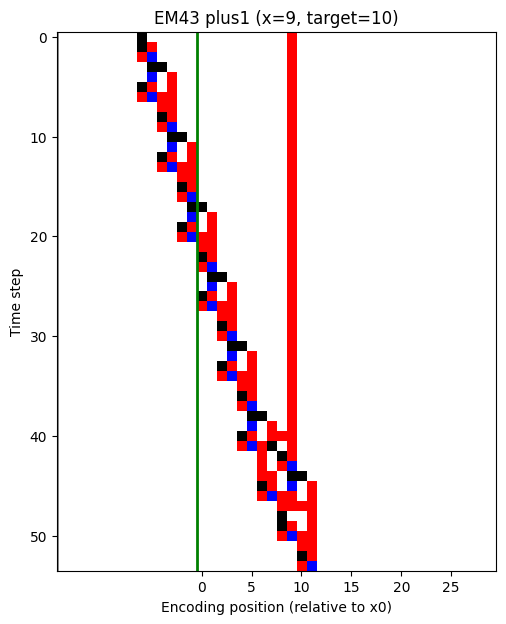

<Figure size 640x480 with 0 Axes>

In [5]:
# =========================
# VISUALIZATION: y = x + 1
# =========================

task_alias = "plus1"
run_id = 1

rule_full, program, meta = load_genome_from_drive(
    task_alias=task_alias,
    run_id=run_id
)

evaluator = EM43NumpyEvaluator(
    Lp=len(program),
    Ls=4,
    T_max=10000,
    right_padding=20,
    extend_margin=3,
    extend_by=20
)

x = 9

target_fn = lambda x: x + 1

enc_vis, target_vis = build_single_input_task(
    inputs=[x],
    target_fn=target_fn
)

out = evaluator.run_single(
    rule_full=rule_full,
    program=program,
    enc=enc_vis[0],
    return_trajectory=True
)

print("Task:", task_alias)
print("Input:", x)
print("Prediction:", out["pred"])
print("Expected:", target_vis[0])
print("Valid:", out["valid"])
print("Halted:", out["halted"])
print("Halt time:", out["halt_time"])

evaluator.plot_trajectory(
    out["trajectory"],
    title=f"EM43 plus1 (x={x}, target={target_vis[0]})",
    figsize=(16, 7),
    tick_step=5
)

plt.gcf().savefig(
    DRIVE_ROOT / "plus1_space_time_x9.png",
    dpi=300,
    bbox_inches="tight"
)

Task: times2
Input: 9
Prediction: 18
Expected: 18
Valid: True
Halt time: 26


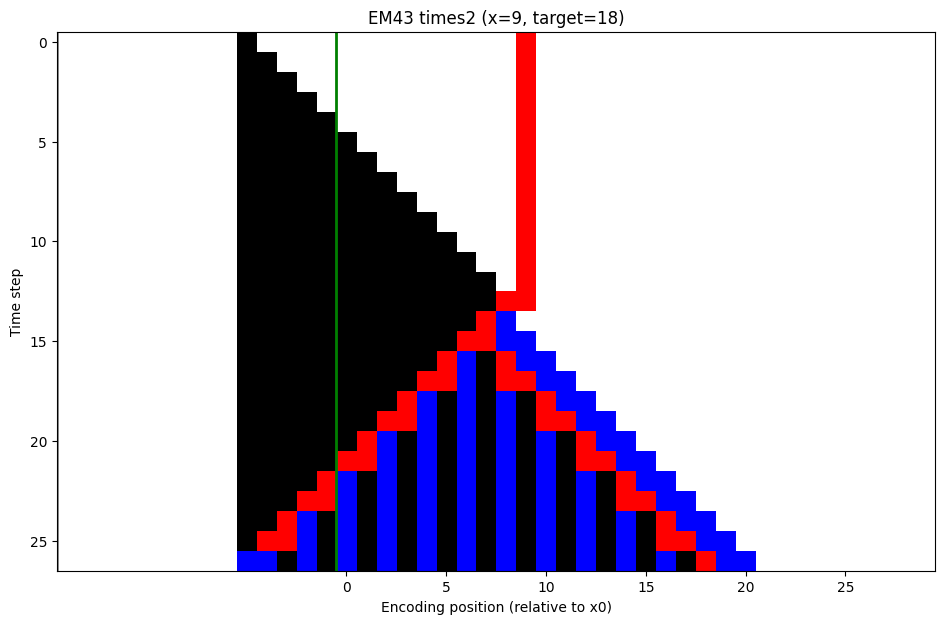

<Figure size 640x480 with 0 Axes>

In [6]:
# =========================
# VISUALIZATION: y = 2x
# =========================

task_alias = "times2"
run_id = 1

rule_full, program, meta = load_genome_from_drive(
    task_alias=task_alias,
    run_id=run_id
)

evaluator = EM43NumpyEvaluator(
    Lp=len(program),
    Ls=4,
    T_max=10000,
    right_padding=20,
    extend_margin=3,
    extend_by=20
)

x = 9

target_fn = lambda x: 2 * x

enc_vis, target_vis = build_single_input_task(
    inputs=[x],
    target_fn=target_fn
)

out = evaluator.run_single(
    rule_full=rule_full,
    program=program,
    enc=enc_vis[0],
    return_trajectory=True
)

print("Task:", task_alias)
print("Input:", x)
print("Prediction:", out["pred"])
print("Expected:", target_vis[0])
print("Valid:", out["valid"])
print("Halt time:", out["halt_time"])

evaluator.plot_trajectory(
    out["trajectory"],
    title=f"EM43 times2 (x={x}, target={target_vis[0]})",
    figsize=(16, 7),
    tick_step=5
)

plt.gcf().savefig(
    DRIVE_ROOT / "times2_space_time_x9.png",
    dpi=300,
    bbox_inches="tight"
)

# Evaluate all saved runs for a task

In [7]:
# =========================
# Evaluate all times2 runs
# =========================

task_alias = "times2"

target_fn = lambda x: 2 * x

# Tập kiểm tra: x = 31 đến 1000
encoded_inputs, targets = build_single_input_task(
    inputs=range(31, 1001),
    target_fn=target_fn,
)

targets = np.asarray(targets, dtype=np.int64)

task_dir = DRIVE_ROOT / task_alias

if not task_dir.exists():
    raise FileNotFoundError(
        f"Task directory not found: {task_dir}"
    )

genome_paths = sorted(
    task_dir.glob(
        f"best_em43_{task_alias}_run_*.npz"
    )
)

print("Found genomes:", len(genome_paths))

if len(genome_paths) != 8:
    raise ValueError(
        f"Expected 8 genomes, found {len(genome_paths)}"
    )

rows = []

print(f"Found {len(genome_paths)} genomes for task '{task_alias}'")
print()

for genome_path in genome_paths:

    data = np.load(genome_path, allow_pickle=True)

    rule_full = np.asarray(
        data["rule_full"], dtype=np.uint8
    ).reshape(-1)

    program = np.asarray(
        data["program"], dtype=np.uint8
    ).reshape(-1)

    enforce_immutables_full(rule_full)

    run_id = (
        int(data["run"])
        if "run" in data
        else int(genome_path.stem.split("_")[-1])
    )

    saved_best_gen = (
        int(data["best_gen"])
        if "best_gen" in data
        else None
    )

    saved_fitness = (
        float(data["fitness"])
        if "fitness" in data
        else None
    )

    saved_mae = (
        float(data["mae"])
        if "mae" in data
        else None
    )

    evaluator = EM43NumpyEvaluator(
        Lp=len(program),
        Ls=4,
        T_max=10000,
        right_padding=20,
        extend_margin=3,
        extend_by=20,
    )

    M = len(encoded_inputs)

    preds = np.full((M,), -1, dtype=np.int64)
    valid = np.zeros((M,), dtype=bool)

    for i in range(M):

        out = evaluator.run_single(
            rule_full=rule_full,
            program=program,
            enc=encoded_inputs[i],
            return_trajectory=False,
        )

        preds[i] = (
            -1 if out["pred"] is None
            else int(out["pred"])
        )

        valid[i] = bool(out["valid"])

    # Tính các chỉ số đánh giá
    correct = valid & (preds == targets)

    accuracy = float(correct.mean())
    valid_fraction = float(valid.mean())
    all_correct = bool(np.all(correct))
    n_wrong = int((~correct).sum())

    # MAE chỉ tính trên những mẫu có output hợp lệ
    if np.any(valid):
        test_mae = float(
            np.mean(
                np.abs(
                    preds[valid] - targets[valid]
                )
            )
        )
    else:
        test_mae = float("nan")

    # Lưu kết quả của run hiện tại
    rows.append([
        run_id,
        len(program),
        saved_best_gen,
        saved_fitness,
        saved_mae,
        accuracy,
        valid_fraction,
        test_mae,
        all_correct,
        n_wrong,
        genome_path.name,
    ])

# Sắp xếp theo run_id
rows.sort(key=lambda r: r[0])

print("Results by run")

print(
    "run | Lp | best_gen | saved_fit | "
    "saved_mae | acc | valid_frac | "
    "test_mae | all_correct | n_wrong | file"
)

for r in rows:
    print(
        f"{r[0]:>3} | "
        f"{r[1]:>2} | "
        f"{str(r[2]):>8} | "
        f"{str(r[3]):>9} | "
        f"{str(r[4]):>9} | "
        f"{r[5]:.6f} | "
        f"{r[6]:.6f} | "
        f"{r[7]:.6f} | "
        f"{str(r[8]):>11} | "
        f"{r[9]:>7} | "
        f"{r[10]}"
    )

# Tìm run có accuracy cao nhất
best_idx = int(np.argmax([r[5] for r in rows]))
best_row = rows[best_idx]

print()
print("Best run on this evaluation set")
print("  run              =", best_row[0])
print("  accuracy         =", best_row[5])
print("  valid_fraction   =", best_row[6])
print("  test_mae         =", best_row[7])
print("  all_correct      =", best_row[8])
print("  n_wrong          =", best_row[9])
print("  genome_file      =", best_row[10])

Found genomes: 8
Found 8 genomes for task 'times2'

Results by run
run | Lp | best_gen | saved_fit | saved_mae | acc | valid_frac | test_mae | all_correct | n_wrong | file
  1 | 10 |       51 | -0.0003000000142492354 |       0.0 | 1.000000 | 1.000000 | 0.000000 |        True |       0 | best_em43_times2_run_001.npz
  2 | 10 |       36 | -0.0003000000142492354 |       0.0 | 1.000000 | 1.000000 | 0.000000 |        True |       0 | best_em43_times2_run_002.npz
  3 | 10 |       38 | -0.0003000000142492354 |       0.0 | 1.000000 | 1.000000 | 0.000000 |        True |       0 | best_em43_times2_run_003.npz
  4 | 10 |       32 | -0.0003000000142492354 |       0.0 | 1.000000 | 1.000000 | 0.000000 |        True |       0 | best_em43_times2_run_004.npz
  5 | 10 |       28 | -0.0003000000142492354 |       0.0 | 1.000000 | 1.000000 | 0.000000 |        True |       0 | best_em43_times2_run_005.npz
  6 | 10 |       40 | -0.0003000000142492354 |       0.0 | 1.000000 | 1.000000 | 0.000000 |        True

In [8]:
import pandas as pd

columns = [
    "run",
    "Lp",
    "best_gen",
    "saved_fit",
    "saved_mae",
    "accuracy",
    "valid_fraction",
    "test_mae",
    "all_correct",
    "n_wrong",
    "genome_file",
]

df = pd.DataFrame(rows, columns=columns)

output_path = (
    DRIVE_ROOT / "times2_extrapolation_results.csv"
)

df.to_csv(output_path, index=False)

print("Saved:", output_path)
display(df)

Saved: /content/drive/MyDrive/EM43/times2_extrapolation_results.csv


,run,Lp,best_gen,saved_fit,saved_mae,accuracy,valid_fraction,test_mae,all_correct,n_wrong,genome_file
0,1,10,51,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_001.npz
1,2,10,36,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_002.npz
2,3,10,38,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_003.npz
3,4,10,32,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_004.npz
4,5,10,28,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_005.npz
5,6,10,40,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_006.npz
6,7,10,48,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_007.npz
7,8,10,30,-0.0003,0.0,1.0,1.0,0.0,True,0,best_em43_times2_run_008.npz



Evaluating: plus1

Evaluating: times2


,task,run,input,expected,predicted,valid,correct,halt_time,extensions,final_length,runtime_median
0,plus1,1,10,11,11,True,True,54,0,45,0.002103
1,plus1,1,20,21,21,True,True,89,0,55,0.004011
2,plus1,1,50,51,51,True,True,194,0,85,0.007195
3,plus1,1,100,101,101,True,True,369,0,135,0.014376
4,plus1,1,200,201,201,True,True,719,0,235,0.015987
5,plus1,1,500,501,501,True,True,1769,0,535,0.049145
6,plus1,1,1000,1001,1001,True,True,3519,0,1035,0.109999
7,times2,1,10,20,20,True,True,28,0,45,0.000691
8,times2,1,20,40,40,True,True,48,1,75,0.001020
9,times2,1,50,100,100,True,True,108,2,125,0.002098


Saved runtime_analysis.csv


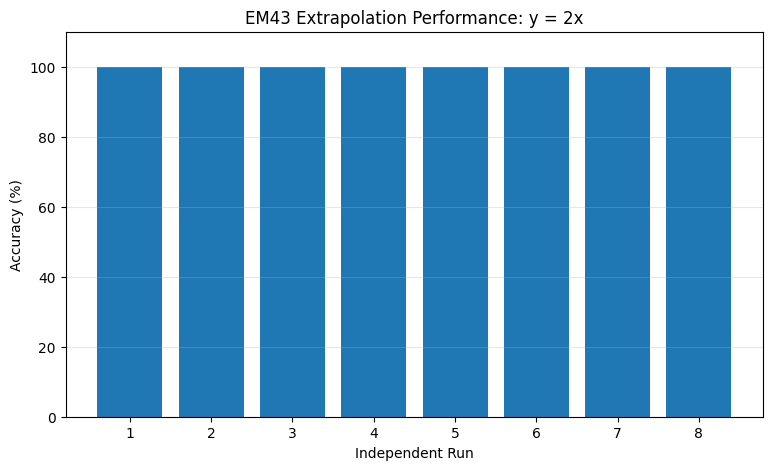

In [9]:
import matplotlib.pyplot as plt
# ============================================
# RUNTIME AND HALTING ANALYSIS
# ============================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

probe_inputs = [
    10, 20, 50, 100, 200, 500, 1000
]

runtime_tasks = {
    "plus1": lambda x: x + 1,
    "times2": lambda x: 2 * x
}

runtime_rows = []

for current_task, target_fn in runtime_tasks.items():

    print("\nEvaluating:", current_task)

    # Load genome RUN 1
    rule_full, program, meta = load_genome_from_drive(
        task_alias=current_task,
        run_id=1
    )

    evaluator = EM43NumpyEvaluator(
        Lp=len(program),
        Ls=4,
        T_max=10000,
        right_padding=20,
        extend_margin=3,
        extend_by=20
    )

    encodings, targets = build_single_input_task(
        inputs=probe_inputs,
        target_fn=target_fn
    )

    for x, enc, expected in zip(
        probe_inputs, encodings, targets
    ):

        # Warm-up
        evaluator.run_single(
            rule_full=rule_full,
            program=program,
            enc=enc,
            return_trajectory=False
        )

        times = []
        last_out = None

        # Repeat 5 times
        for _ in range(5):

            start = time.perf_counter()

            last_out = evaluator.run_single(
                rule_full=rule_full,
                program=program,
                enc=enc,
                return_trajectory=False
            )

            times.append(
                time.perf_counter() - start
            )

        predicted = last_out["pred"]

        correct = bool(
            last_out["valid"]
            and predicted is not None
            and int(predicted) == int(expected)
        )

        runtime_rows.append({
            "task": current_task,
            "run": 1,
            "input": x,
            "expected": int(expected),
            "predicted": predicted,
            "valid": last_out["valid"],
            "correct": correct,
            "halt_time": last_out["halt_time"],
            "extensions": last_out["n_extensions"],
            "final_length": last_out["final_usable_len"],
            "runtime_median": float(np.median(times))
        })

# Create dataframe
runtime_df = pd.DataFrame(runtime_rows)

display(runtime_df)

# Save CSV
runtime_df.to_csv(
    DRIVE_ROOT / "runtime_analysis.csv",
    index=False
)

print("Saved runtime_analysis.csv")

plt.figure(figsize=(9, 5))

plt.bar(
    df["run"],
    df["accuracy"] * 100
)

plt.xlabel("Independent Run")
plt.ylabel("Accuracy (%)")
plt.title("EM43 Extrapolation Performance: y = 2x")

plt.xticks(df["run"])
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    DRIVE_ROOT / "times2_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# ============================================
# EXTENDED EXTRAPOLATION TEST
# ============================================

import time
import pandas as pd
import numpy as np

stress_inputs = [1001, 1500, 2000, 5000]

tasks = {
    "plus1": lambda x: x + 1,
    "times2": lambda x: 2 * x
}

stress_rows = []

# Test run 1 first
run_id = 1

for task_alias, target_fn in tasks.items():

    print("\n" + "=" * 60)
    print("TASK:", task_alias)
    print("=" * 60)

    # Load trained genome
    rule_full, program, meta = load_genome_from_drive(
        task_alias=task_alias,
        run_id=run_id
    )

    # Initialize evaluator
    evaluator = EM43NumpyEvaluator(
        Lp=len(program),
        Ls=4,
        T_max=10000,
        right_padding=20,
        extend_margin=3,
        extend_by=20
    )

    # Create test data
    encodings, targets = build_single_input_task(
        inputs=stress_inputs,
        target_fn=target_fn
    )

    for x, enc, expected in zip(
        stress_inputs, encodings, targets
    ):

        start = time.perf_counter()

        out = evaluator.run_single(
            rule_full=rule_full,
            program=program,
            enc=enc,
            return_trajectory=False
        )

        elapsed = time.perf_counter() - start

        predicted = (
            None if out["pred"] is None
            else int(out["pred"])
        )

        correct = (
            out["valid"]
            and predicted == int(expected)
        )

        row = {
            "task": task_alias,
            "run": run_id,
            "input": x,
            "expected": int(expected),
            "predicted": predicted,
            "valid": out["valid"],
            "correct": correct,
            "halt_time": out["halt_time"],
            "extensions": out["n_extensions"],
            "final_length": out["final_usable_len"],
            "time_sec": elapsed
        }

        stress_rows.append(row)

        print(row)

# Create result dataframe
stress_df = pd.DataFrame(stress_rows)

display(stress_df)

# Save
output_path = (
    DRIVE_ROOT / "extended_extrapolation_run1.csv"
)

stress_df.to_csv(output_path, index=False)

print("Saved:", output_path)


TASK: plus1
{'task': 'plus1', 'run': 1, 'input': 1001, 'expected': 1002, 'predicted': 1002, 'valid': True, 'correct': True, 'halt_time': 3525, 'extensions': 0, 'final_length': 1036, 'time_sec': 0.11418058600020231}
{'task': 'plus1', 'run': 1, 'input': 1500, 'expected': 1501, 'predicted': 1501, 'valid': True, 'correct': True, 'halt_time': 5269, 'extensions': 0, 'final_length': 1535, 'time_sec': 0.1841091750002306}
{'task': 'plus1', 'run': 1, 'input': 2000, 'expected': 2001, 'predicted': 2001, 'valid': True, 'correct': True, 'halt_time': 7019, 'extensions': 0, 'final_length': 2035, 'time_sec': 0.2555963340000744}
{'task': 'plus1', 'run': 1, 'input': 5000, 'expected': 5001, 'predicted': None, 'valid': False, 'correct': False, 'halt_time': None, 'extensions': 0, 'final_length': 5035, 'time_sec': 0.5403274210002564}

TASK: times2
{'task': 'times2', 'run': 1, 'input': 1001, 'expected': 2002, 'predicted': 2002, 'valid': True, 'correct': True, 'halt_time': 2010, 'extensions': 50, 'final_lengt

,task,run,input,expected,predicted,valid,correct,halt_time,extensions,final_length,time_sec
0,plus1,1,1001,1002,1002.0,True,True,3525.0,0,1036,0.114181
1,plus1,1,1500,1501,1501.0,True,True,5269.0,0,1535,0.184109
2,plus1,1,2000,2001,2001.0,True,True,7019.0,0,2035,0.255596
3,plus1,1,5000,5001,NaN,False,False,NaN,0,5035,0.540327
4,times2,1,1001,2002,2002.0,True,True,2010.0,50,2036,0.067639
5,times2,1,1500,3000,3000.0,True,True,3008.0,75,3035,0.110174
6,times2,1,2000,4000,4000.0,True,True,4008.0,100,4035,0.164332
7,times2,1,5000,10000,NaN,False,False,NaN,249,10015,0.705892


Saved: /content/drive/MyDrive/EM43/extended_extrapolation_run1.csv


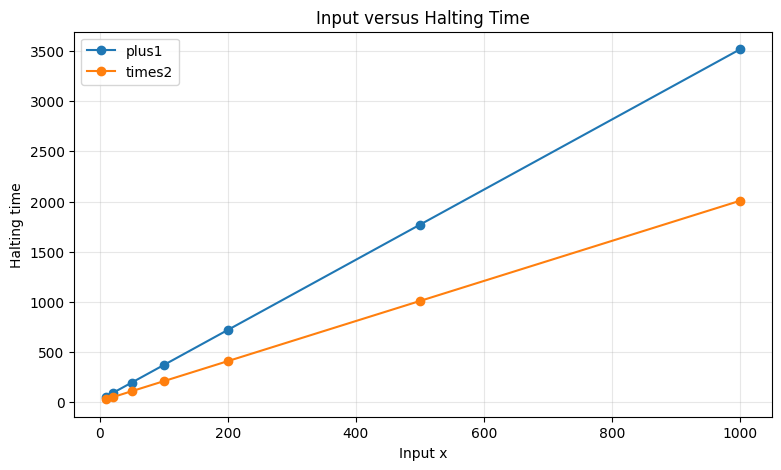

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for task in runtime_df["task"].unique():

    subset = runtime_df[
        runtime_df["task"] == task
    ]

    plt.plot(
        subset["input"],
        subset["halt_time"],
        marker="o",
        label=task
    )

plt.xlabel("Input x")
plt.ylabel("Halting time")
plt.title("Input versus Halting Time")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    DRIVE_ROOT / "input_halt_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

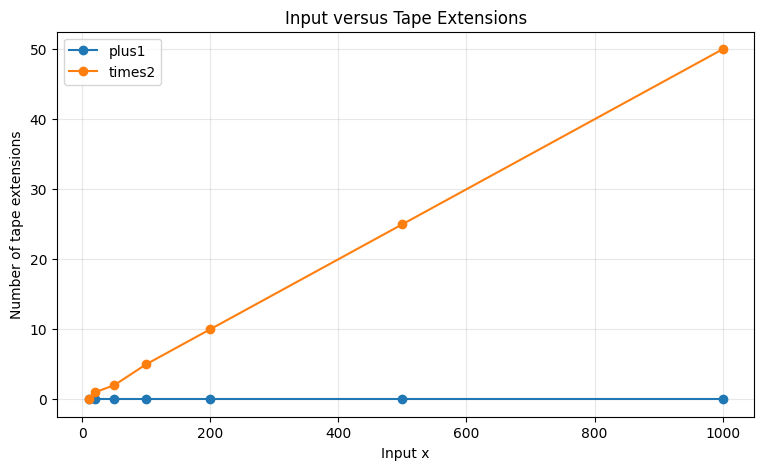

In [12]:
plt.figure(figsize=(9, 5))

for task in runtime_df["task"].unique():

    subset = runtime_df[
        runtime_df["task"] == task
    ]

    plt.plot(
        subset["input"],
        subset["extensions"],
        marker="o",
        label=task
    )

plt.xlabel("Input x")
plt.ylabel("Number of tape extensions")
plt.title("Input versus Tape Extensions")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    DRIVE_ROOT / "input_extensions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()